# 動画で学んだAIは「物理的にありえない出来事」に驚くか？（直観物理・JEPA）

- **分類**：JEPA × Physical AI ・ 初心者向けおすすめ順 **1番**
- **チュートリアル**：[facebookresearch/jepa-intuitive-physics](https://github.com/facebookresearch/jepa-intuitive-physics) の `figures.ipynb`（論文の全モデルの評価結果が同梱されていて、図を再現できる）
- **実行環境**：Google Colaboratory（CPUのみ）・約5分
- **Physical AI との関係**：ロボットが現実世界で動くには「物は突然消えない」、「固い物はすり抜けない」、「支えがないと落ちる」といった**直観物理**が必要となる。直感物理は人間でも特に赤ちゃんの心理学実験と同じと考えられる。今回の実験は生成AIがそれを身につけているかを、次に示す9つの物理性質から調べた。

## 前提知識：期待違反（Violation of Expectation）
ありえる動画とありえない動画（物が消える、壁をすり抜ける など）を見せ、**予測が外れた度合い（驚き）**を比べる。ありえない方で驚きが大きければ「物理を理解している」と判定する。JEPA は表現の予測誤差を「驚き」として使えるものと仮定する。

## 仮説
**V-JEPA は、9つの物理の性質すべてで、学習していないネットワークより正解率が高い。**（＝どの性質も、動画から学べている）

9つの性質：物体の永続性・連続性・形の不変性・色の不変性・支え・慣性・重力・固さ・衝突

## 検証のしかた
- 同梱データには、**学習していない（ランダムな重みの）ネットワーク20個**の結果が入っている。学習しなくても、偶然これくらいは正解できる、という基準になる。
- その20個の **平均 ＋ 標準偏差の2倍** を「学習なしでも偶然出せる範囲の上限」とする（20個のうち約95%がこの範囲に収まる目安）。
- 性質ごとに、V-JEPA がこの上限を**超えたら「学べている 〇」、超えなければ「学べていない ×」**と判定する。
- **9つすべてが 〇 なら仮説は支持される**、1つでも×があれば支持されないとする。

## 本notebookの構成
- **【A】チュートリアル**：figures.ipynb の最初の8セル（論文の図1）をそのまま実行
- **【B】追加実験** ：仮説の検証（追加コードは1つ）
- **【C】考察のポイント** ／ **レポート用まとめ**

## 対応する論文

### 主論文
**Intuitive physics understanding emerges from self-supervised pretraining on natural videos**
- 著者：Quentin Garrido, Nicolas Ballas, Mahmoud Assran, Adrien Bardes, Laurent Najman, Michael Rabbat, Emmanuel Dupoux, Yann LeCun
- 発表：arXiv preprint, 2025年2月
- リンク：https://arxiv.org/abs/2502.11831
- 概要：物体が消える・すり抜けるなど物理的にありえない動画と、ありえる動画を見せ、予測誤差（驚き）の差で直観物理の理解を測る「期待違反」の評価。自然な動画で表現を予測して学んだ V-JEPA は高い正解率を示し、画素を予測するモデルや大規模な動画LLMは偶然に近かったと報告。
- このノートとの対応：【A】は公式リポジトリの figures.ipynb（論文の図1の再現）。【B】は同梱の評価結果を、物理の性質ごと・モデルの大きさ・学習データ量・文脈の長さで集計し直している。

### 関連論文
**Revisiting Feature Prediction for Learning Visual Representations from Video（V-JEPA）**
- 著者：Adrien Bardes, Quentin Garrido, Jean Ponce, Xinlei Chen, Michael Rabbat, Yann LeCun ほか
- 発表：arXiv preprint, 2024年
- リンク：https://arxiv.org/abs/2404.08471
- 概要：動画で特徴（表現）を予測して学ぶ V-JEPA の原論文。
- このノートとの対応：【A】【B】で評価されている V-JEPA モデルの学習方法。


## チュートリアル（Github）
### A-1. データの取得（README：`tar -xzvf data_intphys.tar.gz` で展開）

In [1]:
!git clone -q https://github.com/facebookresearch/jepa-intuitive-physics.git
%cd jepa-intuitive-physics
# data_intphys.tar.gz（約100MB）が clone で取れていない場合に備えて直接ダウンロード
!test -s data_intphys.tar.gz && tar -tzf data_intphys.tar.gz > /dev/null 2>&1 || wget -q -O data_intphys.tar.gz https://github.com/facebookresearch/jepa-intuitive-physics/raw/main/data_intphys.tar.gz
!tar -xzf data_intphys.tar.gz 2>/dev/null; ls data_intphys | head -20

/content/jepa-intuitive-physics
gemini_1.5_pro
qwen2vl_72b
qwen2vl_72b_property_prompt
qwen2vl_7b
videomaev2_g
vit-b-rope-howto
vit-h-rope-howto
vit-h-rope-vm2m
vit-l-rope-howto
vit-l-rope-howto-0
vit-l-rope-howto-0_1p_vid
vit-l-rope-howto-1
vit-l-rope-howto-10p_frame
vit-l-rope-howto-10p_vid
vit-l-rope-howto-1p_vid
vit-l-rope-howto-2
vit-l-rope-howto-25p_frame
vit-l-rope-howto-25p_vid
vit-l-rope-howto-2p_frame
vit-l-rope-howto-3


### GithubのA-2. figures.ipynb の最初の8セル

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm
from scipy.stats import bootstrap
from scipy.stats import ttest_rel, ttest_1samp
import torch
import os


from matplotlib import font_manager
# 🔧 元は作者のPC上のフォント（/Users/garridoq/fonts/helvetica.ttf）を読み込む4行。Colab には無いので削除
plt.rcParams.update({'font.size': 13})

In [3]:
from pathlib import Path
root = Path("./data_intphys")
os.makedirs('./figures',exist_ok=True)

In [4]:
from scipy import stats

def hedges_g(data1, data2):
    """
    Calculate Hedge's g for effect size between two groups using raw data.
    Parameters:
    data1 (array-like): data of the first group
    data2 (array-like): data of the second group
    Returns:
    float: Hedge's g
    """
    mean1 = np.mean(data1)
    mean2 = np.mean(data2)
    sd1 = np.std(data1, ddof=1)  # ddof=1 for sample standard deviation
    sd2 = np.std(data2, ddof=1)

    n1 = len(data1)
    n2 = len(data2)

    s_pooled = np.sqrt(((n1 - 1) * sd1**2 + (n2 - 1) * sd2**2) / (n1 + n2 - 2))

    # Calculate Cohen's d
    d = (mean1 - mean2) / s_pooled

    correction = 1 - (3 / (4*(n1 + n2) - 9))
    #n= n1+n2
    #correction = ((n-3)/(n-2.25))*np.sqrt((n-2)/n)

    # Calculate Hedge's g
    g = d * correction

    se = np.sqrt((n1 + n2) / (n1 * n2) + (g**2 / (2 * (n1 + n2))))

    # Confidence interval
    alpha = 0.05
    z = stats.norm.ppf(1 - alpha / 2)
    err = z*se
    return g,err

In [5]:
categories = [
        "Object Permanence",
        "Continuity",
        "Shape Constancy",
        "Color Constancy",
        "Support",
        "Inertia",
        "Gravity",
        "Solidity",
        "Collision",
]
mappings = {
    "intphys":{'O1':["Object Permanence"],
               'O2':["Shape Constancy"],
               'O3':["Continuity"]},
    "inflevel":{'continuity':["Object Permanence"],
                'solidity':["Solidity"],
                'gravity':["Gravity"]},
    "grasp":{'Collision':['Collision'],
            'Continuity':['Continuity'],
            'Gravity':['Gravity'],
            'GravityContinuity':['Gravity','Continuity'],
            'GravityInertia':['Gravity','Inertia'],
            'GravityInertia2':['Gravity','Inertia'],
            'GravitySupport':['Gravity','Support'],
            'Inertia':['Inertia'],
            'Inertia2':['Inertia'],
            'ObjectPermanence':['Object Permanence'],
            'ObjectPermanence2':['Object Permanence'],
            'ObjectPermanence3':['Object Permanence'],
            'SolidityContinuity':['Solidity','Continuity'],
            'SolidityContinuity2':['Solidity','Continuity'],
            'Unchangeableness':['Color Constancy'],
            'Unchangeableness2':['Color Constancy']}}

In [6]:
from scipy.stats import norm
from scipy.stats import bootstrap

def plot_hist_g(accs,perfs_rand,labels,title,colors=["#d1ccdc"]+["#3292a8","#ffa600","#994636","#a6d3a0","#d4b483","#7d1128","#b4cded","#b279a7","#bfcc94"]*10,plot_legend=False,do_bootstrap=False,chance=True):
    labels_cat = ["IntPhys","GRASP","InfLevel-lab"]
    x = np.arange(len(labels_cat))  # the label locations
    width = 0.7/(len(accs)+1)  # the width of the bars
    plt.grid(zorder=1)
    ax=plt.gca()
    start = width*(len(accs)+1)/2-width/2

    rects1 = ax.bar(x-start , perfs_rand.mean(1), width,yerr=perfs_rand.std(1)*1.96,capsize=4, label=labels[0],zorder=2,color=colors[0])
    #plt.scatter((x-start).repeat(perfs_rand.shape[1])+np.random.uniform(-1,1,(len(x)*perfs_rand.shape[1],))*width/7,perfs_rand.flatten(),zorder=10,alpha=0.2,color="#4c4c4c")

    for i,acc in enumerate(accs):
        if do_bootstrap:
            yerr_lower = []
            yerr_upper = []
            lengths = [360//2,4096//2,(2268+912+2592)//2]
            for j,acc_ in enumerate(acc):
                syn_preds = np.zeros((lengths[j],))
                syn_preds[:int(acc_/100*lengths[j])] = 1
                b = bootstrap((syn_preds,),np.mean)
                yerr_lower.append(acc_ - b.confidence_interval.low*100)
                yerr_upper.append(b.confidence_interval.high*100 - acc_)
            yerr=[yerr_lower, yerr_upper]
            if i == len(accs) - 1:
                print(np.array(acc) - np.array(yerr_lower))
                print(np.array(acc) + np.array(yerr_upper))
            rects1 = ax.bar(x-start+(i+1)*width , acc, width,yerr=yerr,capsize=4,label=labels[i+1],zorder=2,color=colors[i+1])
        else:
            rects1 = ax.bar(x-start+(i+1)*width , acc, width,label=labels[i+1],zorder=2,color=colors[i+1])
    if chance:
        plt.axhline(50,color="red",linestyle="--",label="Chance level")
    # Show the plot
    ax.set_ylabel('Pairwise classification accuracy (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(labels_cat,rotation=0,ha="center")
    plt.xlabel("Dataset")
    plt.title(title)
    plt.ylim([40,None])
    #plt.text(1.5, 45, 'Chance level', color='red', fontsize=12)
    if plot_legend:
        legend=plt.legend(loc="upper right",bbox_to_anchor=(1.01, 1.01))
        legend.get_frame().set_facecolor('white')
        legend.get_frame().set_alpha(1)
        legend.get_frame().set_edgecolor('gray')

In [7]:
def get_average_acc(root,exp,dataset,key_metric="Relative Accuracy (avg)"):
    path = root/exp/dataset/"performance.csv"
    df = pd.read_csv(path,sep=';',skiprows=0)
    props = df["Block"].unique()
    perfs = []
    for prop in props:
        targets = mappings[dataset][prop]
        try:
            acc=df[df["Block"] == prop][key_metric].max()
        except:
            acc=df[df["Block"] == prop].iloc[-1][key_metric]

        perfs.append(acc)
    return np.mean(perfs)

[95.55555556 64.30664062 59.7020097 ]
[99.44444444 68.40820312 63.27096327]


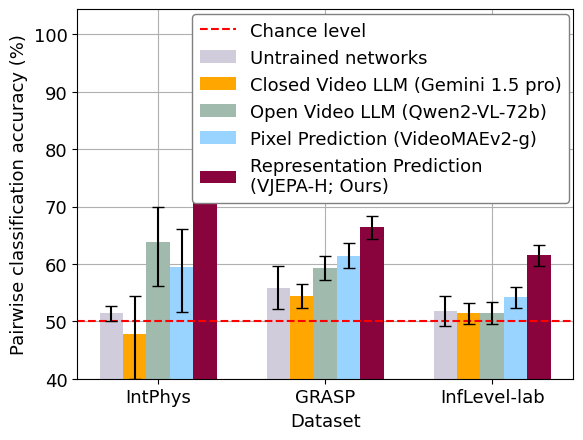

In [8]:
key_metric = "Relative Accuracy (avg)"
perfs_rand = []
for dataset in ["intphys","grasp","inflevel"]:
    perfs_per_dataset = []
    perf_by_category = { prop:[] for prop in categories}
    for exp in [f"vit-l-rope-random-{i}" for i in range(20)]:
        perf_by_category_model = get_average_acc(root,exp,dataset,key_metric=key_metric)
        perfs_per_dataset.append(perf_by_category_model)
    perfs_rand.append(perfs_per_dataset)

perfs_methods = []
for dataset in ["intphys","grasp","inflevel"]:
    perfs_per_dataset = []
    perf_by_category = { prop:[] for prop in categories}
    for exp in ["gemini_1.5_pro","qwen2vl_72b","videomaev2_g",f"vit-h-rope-vm2m"]:
        perf = get_average_acc(root,exp,dataset,key_metric=key_metric)
        perfs_per_dataset.append(perf)
    perfs_methods.append(perfs_per_dataset)

plot_hist_g(np.array(perfs_methods).T,np.array(perfs_rand),
            ["Untrained networks","Closed Video LLM (Gemini 1.5 pro)","Open Video LLM (Qwen2-VL-72b)","Pixel Prediction (VideoMAEv2-g)","Representation Prediction\n(VJEPA-H; Ours)"],
#            ["Untrained networks","Closed Video LLM","Open Video LLM","Pixel Space Prediction","Representation Space Prediction\n(Ours)"],
            "",
            colors=["#d1ccdc","#ffa600","#a0bbad","#99d3ff","#89043d"],
            plot_legend=True,do_bootstrap=True)

plt.savefig("./figures/global_results_1.pdf",bbox_inches="tight")
plt.show()

## 追加実験：仮説検証

### 追加コードの内容
このセルだけで、検証の4つの手順をすべて行います。
1. **性質ごとの正解率を出す**（`per_property`）：公式の `get_average_acc()` は、3つのデータセット（IntPhys・GRASP・InfLevel-lab）の正解率を平均して1つの数にしている。ここでは平均せずに、公式の対応表 `mappings` を使って9つの性質に振り分ける。各ブロックで最も良かった文脈の長さの値を使うのは公式と同じ。
2. **V-JEPA と、学習していないネットワーク20個**の性質ごとの正解率を出す。
3. **判定する**：20個の「平均 ＋ 標準偏差の2倍」を上限とし、V-JEPA が上回れば 〇、そうでなければ ×。
4. **結果を示す**：判定表、仮説が支持されたかの1文、グラフ（緑＝学べている、赤＝学べていない。黒い点と縦線＝学習なしの平均と偶然の範囲）。

,V-JEPA-H (%),学習なしの平均 (%),偶然の範囲の上限 (%),上限との差 (pt),判定
Object Permanence,79.4,53.2,61.2,18.2,〇 学べている
Continuity,77.9,54.3,62.5,15.4,〇 学べている
Shape Constancy,100.0,51.7,54.1,45.9,〇 学べている
Color Constancy,62.9,63.9,92.5,-29.6,× 学べていない
Support,89.1,58.4,80.0,9.1,〇 学べている
Inertia,54.7,54.3,62.8,-8.1,× 学べていない
Gravity,64.5,54.6,62.1,2.4,〇 学べている
Solidity,66.1,54.9,64.9,1.3,〇 学べている
Collision,69.5,54.5,82.5,-13.0,× 学べていない


9つの性質のうち 6 個で 〇（学べている）、3 個で ×（学べていない）
× の性質: Color Constancy、Inertia、Collision
→ 仮説は 支持されなかった（学べていない性質がある）


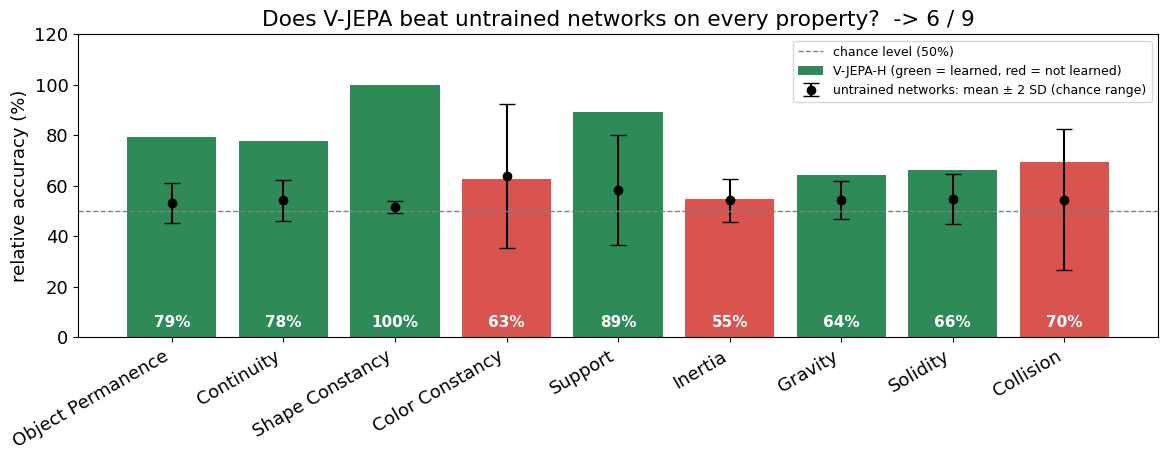

In [11]:
# 追加コード：仮説「V-JEPA は9つの物理の性質すべてで、学習していないネットワークより正解率が高い」の検証

# 1. 性質ごとの正解率（3つのデータセットのブロックを、公式の mappings で9つの性質に振り分ける）
def per_property(exp, key_metric="Relative Accuracy (avg)"):
    acc = {c: [] for c in categories}
    for dataset in ["intphys", "grasp", "inflevel"]:
        df = pd.read_csv(root / exp / dataset / "performance.csv", sep=';')
        for prop in df["Block"].unique():
            best = df[df["Block"] == prop][key_metric].max()      # 公式と同じく、最も良かった文脈の長さの値
            for cat in mappings[dataset][prop]:
                acc[cat].append(best)
    return pd.Series({c: np.mean(v) for c, v in acc.items()})

# 2. V-JEPA と、学習していないネットワーク20個
vjepa = per_property("vit-h-rope-vm2m")
untrained = pd.DataFrame([per_property(f"vit-l-rope-random-{i}") for i in range(20)])

# 3. 判定：「学習なしでも偶然出せる範囲」の上限（平均 + 標準偏差の2倍）を超えたら ✅
upper = untrained.mean() + 2 * untrained.std()
learned = vjepa > upper
result = pd.DataFrame({"V-JEPA-H (%)": vjepa,
                       "学習なしの平均 (%)": untrained.mean(),
                       "偶然の範囲の上限 (%)": upper,
                       "上限との差 (pt)": vjepa - upper,
                       "判定": np.where(learned, "〇 学べている", "× 学べていない")})
display(result.round(1))

# 4. 仮説の判定
print(f"9つの性質のうち {learned.sum()} 個で 〇（学べている）、{(~learned).sum()} 個で ×（学べていない）")
print("× の性質:", "、".join(vjepa.index[~learned]) if (~learned).any() else "なし")
print("→ 仮説は", "支持された" if learned.all() else "支持されなかった（学べていない性質がある）")

# グラフ
x = np.arange(len(vjepa))
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x, vjepa, color=np.where(learned, "#2e8b57", "#d9534f"), label="V-JEPA-H (green = learned, red = not learned)")
ax.errorbar(x, untrained.mean(), yerr=2 * untrained.std(), fmt="o", color="black", capsize=6,
            label="untrained networks: mean ± 2 SD (chance range)")
ax.axhline(50, ls="--", c="gray", lw=1, label="chance level (50%)")
for i, v in enumerate(vjepa):
    ax.text(i, 4, f"{v:.0f}%", ha="center", color="white", fontsize=11, fontweight="bold")   # 数値は棒の下側に白字で
ax.set_xticks(x); ax.set_xticklabels(vjepa.index, rotation=30, ha="right")
ax.set_ylabel("relative accuracy (%)"); ax.set_ylim(0, 120); ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"Does V-JEPA beat untrained networks on every property?  -> {learned.sum()} / {len(vjepa)}")
plt.tight_layout(); plt.savefig("./figures/PA1_hypothesis.png", dpi=120); plt.show()

##### "Object Permanence": "物体の永続性", "Continuity": "連続性", "Shape Constancy": "形の不変性","Color Constancy": "色の不変性", "Support": "支え", "Inertia": "慣性","Gravity": "重力", "Solidity": "固さ", "Collision": "衝突"

## 【C】考察のヒント
- **判定の結果**：作成時に同梱データで実行した結果では、9つのうち **6つが 〇、3つ（色の不変性・慣性・衝突）が ×** で、仮説は支持されなかった。
- **× の理由は2種類ある**ので、分けて考えると深い考察になる。
  - **慣性**：V-JEPA 54.7% と、学習なしの平均 54.3% とほぼ同じ。学習しても**まったく伸びていない**。「勢いを保って動き続ける」という動きの法則は、動画を見るだけでは身につきにくいのかもしれない。
  - **色の不変性・衝突**：V-JEPA の値（62.9%・69.5%）自体は偶然（50%）より高いが、学習なしのネットワークのばらつきが大きい（標準偏差 約14pt）ため、上限（92.5%・82.5%）を超えられなかった。**学習なしでも偶然高い値が出やすい課題**で、評価が難しい性質だと言える。
- **ぎりぎりの 〇**：重力（上限との差 +2.4pt）と固さ（+1.3pt）は、わずかに上回っただけ。上限を「標準偏差の3倍」にすると × に変わるので、判定の基準によって結論が変わりうる。
- 公式の図1（【A】）では、3つのデータセットの平均で見ると V-JEPA が最も高い。**平均では優秀でも、性質ごとに見ると弱点がある**ことが、追加実験でわかった点。
- **わからなかったこと（例）**：なぜ慣性は学べないのか（学習方法の問題か、評価動画の問題か）。学習なしのネットワークが「色の不変性」で高い値を出せてしまうのはなぜか。

## まとめ

### (1) 試したこと
論文「Intuitive physics understanding emerges from self-supervised pretraining on natural videos」（Garrido et al., 2025, arXiv:2502.11831）の公式リポジトリ（GitHub: facebookresearch/jepa-intuitive-physics の `figures.ipynb`）を Google Colab で動かし、論文の図1を再現しました。

さらに独自の仮説「V-JEPA は、9つの物理の性質すべてで、学習していないネットワークより正解率が高い（＝どの性質も動画から学べている）」を立て、同梱の評価結果を使って検証しました。

### (2) 手続き
- **実行環境**：Google Colab（CPU） のみ。所要時間は約5分。
- **【A】チュートリアル**
  - A-1：リポジトリを取得し、同梱の評価結果 `data_intphys.tar.gz`（約100MB）を展開しました。
  - A-2：`figures.ipynb` の最初の8セル（図1）をそのまま実行しました。変更は、作者のPC上のフォントを読み込む4行を削除した1か所だけです。
- **【B】追加コード（1つ）**
  - 公式の対応表 `mappings` を使い、3つのデータセットのブロックを9つの物理の性質に振り分けて、性質ごとの正解率を出しました。
  - 学習していないネットワーク20個の「平均 ＋ 標準偏差の2倍」を「学習なしでも偶然出せる範囲の上限」とし、V-JEPA-H がそれを超えたら「学べている 〇」と判定しました。9つすべてが〇 なら仮説は支持、とします。
- **設定**：正解率は公式と同じ「Relative Accuracy (avg)」。ハイパーパラメータの変更はありません（学習はせず、公開済みの評価結果を集計しています）。

### (3) わかったこと
- **仮説は支持されませんでした。** 9つのうち6つで 〇、3つで × でした。
  - 〇：形の不変性 100.0%（上限 54.1%）、物体の永続性 79.4%（上限 61.2%）、連続性 77.9%（上限 62.5%）、支え 89.1%（上限 80.0%）、重力 64.5%（上限 62.1%）、固さ 66.1%（上限 64.9%）
  - ×：慣性 54.7%（上限 62.8%）、衝突 69.5%（上限 82.5%）、色の不変性 62.9%（上限 92.5%）
- **× の理由は2種類ありました。**
  - 慣性は、V-JEPA（54.7%）と学習なしの平均（54.3%）がほぼ同じで、学習してもまったく伸びていませんでした。勢いを保って動き続けるという「動きの法則」は、動画を見るだけでは身につきにくいと考えられます。
  - 衝突と色の不変性は、V-JEPA の値は偶然（50%）より高いものの、学習なしのネットワークのばらつきが大きく（標準偏差 約14pt）、上限を超えられませんでした。学習なしでも偶然高い値が出やすい、評価の難しい性質です。
- **予想と違った点**：論文の図1では、3つのデータセットの平均で V-JEPA が最も高い正解率でした。しかし性質ごとに分けると弱点があり、**平均だけを見ると見落とす**ことがわかりました。また、重力（+2.4pt）と固さ（+1.3pt）はわずかに上限を超えただけで、判定の基準を厳しくすると結論が変わりえます。

### (3) わからなかったこと
- なぜ慣性は、動画で学習しても学習なしと変わらないのか。学習方法（何を予測させるか）に原因があるのか、根本的に評価用の動画の作り方に原因があるのか、どれが要因かが今の条件では判断がつけられないため。
- 学習していないネットワークが、色の不変性で高い値（20個の中の最大で 87.9%、最小は 35.5%）を出せてしまうのはなぜか。この評価方法でその性質の理解を正しく測れているのかは実施環境に依存すると思われる。